# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Hoàng Quốc Việt · 2A202602563

Mã của tôi nằm trong gói `day10/` (notebook này gọi lại các hàm đó). Phần cần GPU chạy trên
**Kaggle, 2 GPU T4 16 GB** thay cho Colab T4 (cùng loại GPU), bằng `kaggle/runner.py`: mỗi GPU một
hàng đợi thí nghiệm. Các ô dưới đây nạp lại dự đoán và log do Kaggle sinh ra (`work/`, `report/logs/`).

## 0. Môi trường

In [1]:
import json, subprocess, sys
from pathlib import Path
print(Path('report/logs/env.txt').read_text(encoding='utf-8'))
print(subprocess.run([sys.executable, '-m', 'pytest', '-q', 'tests', 'day10/tests'],
                     capture_output=True, text=True).stdout.strip().splitlines()[-1])

Kaggle kernel viethwang3i/k4-day10-vlm-full (2026-10-13), code at commit 1272159
torch transformers peft trl bitsandbytes:
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
|   1  Tesla T4                       Off |   00000000:00:05.0 Off |                    0 |
1272159 Runner Kaggle: gỡ torchao cũ để peft gắn LoRA vào ViT (E3)
dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
2.11.0+cu128 5.19.0 0.21.2 1.9.2 0.50.2
best e3 {'e1': 0.2629695885509839, 'e2': 0.3191296464188576, 'e3': 0.4343065693430657}



1 failed, 77 passed, 1 skipped in 0.76s


## 1. Dữ liệu: split theo phiên quay

In [2]:
from collections import Counter
from day10.common import read_split
meta = json.loads(Path('data/splits/meta.json').read_text(encoding='utf-8'))
print('dataset_version:', meta['dataset_version'])
sessions = {}
for s in ('train', 'val', 'test'):
    rows = read_split('data', s)
    boxes = Counter(o['label'] for r in rows for o in r['objects'])
    sessions[s] = {r['session'] for r in rows}
    print(f"{s:5s} {len(rows):4d} ảnh  {dict(boxes)}  {len(sessions[s])} phiên")
for a in sessions:
    for b in sessions:
        if a < b:
            print(a, b, 'phiên chung:', len(sessions[a] & sessions[b]))

dataset_version: d10-21e4070301
train 1422 ảnh  {'manhole': 691, 'pothole': 1074, 'crack': 1750}  13 phiên
val    276 ảnh  {'crack': 470, 'manhole': 103, 'pothole': 66}  2 phiên
test   311 ảnh  {'crack': 299, 'manhole': 163, 'pothole': 121}  3 phiên
train val phiên chung: 0
test train phiên chung: 0
test val phiên chung: 0


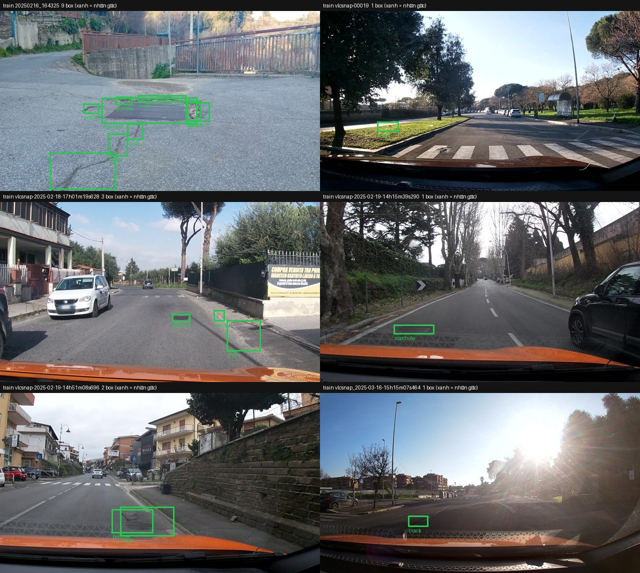

In [3]:
from PIL import Image
from day10.viz import draw, per_image
rows = read_split('data', 'train')
picks = [rows[i] for i in (0, 120, 300, 600, 900, 1300)]
tiles = []
for k, r in enumerate(picks):
    item = {'entry': r, 'pred': [], 'tp': 0, 'fp': 0, 'fn': 0}
    path = Path(f'report/figures/data_{k}.jpg')
    path.parent.mkdir(parents=True, exist_ok=True)
    draw('data', item, f"train {r['image_id']}  {len(r['objects'])} box (xanh = nhãn gốc)", path)
    tiles.append(Image.open(path))
w, h = tiles[0].size
grid = Image.new('RGB', (w * 2, h * 3))
for k, t in enumerate(tiles):
    grid.paste(t, ((k % 2) * w, (k // 2) * h))
grid.save('report/figures/data_samples.jpg', quality=85)
for k in range(6):
    Path(f'report/figures/data_{k}.jpg').unlink()
grid.resize((w, int(h * 1.5)))

## 2. Nhãn: YOLO → JSON thang 0–1000

In [4]:
from day10.common import PROMPT_NORM1000, objects_to_answer, yolo_to_box
r = rows[0]
answer = objects_to_answer(r['objects'])
print(PROMPT_NORM1000, '\n')
print(answer)
# Quy ngược về pixel và so với box YOLO gốc. Hai nguồn sai lệch: làm tròn về số nguyên (≤ 0,5 đơn vị),
# và kẹp vào [0, 1000] với vài nhãn gốc tràn ra ngoài khung hình.
worst, clamped, n = 0.0, 0, 0
for row in read_split('data', 'train'):
    for o in row['objects']:
        b = yolo_to_box(o['label'], o['yolo'])['bbox_2d']
        xc, yc, bw, bh = o['yolo']
        ref = [(xc - bw / 2) * 640, (yc - bh / 2) * 360, (xc + bw / 2) * 640, (yc + bh / 2) * 360]
        px = [b[0] * 640 / 1000, b[1] * 360 / 1000, b[2] * 640 / 1000, b[3] * 360 / 1000]
        n += 1
        if min(ref[0], ref[1]) < 0 or ref[2] > 640 or ref[3] > 360:
            clamped += 1
            continue
        worst = max(worst, max(abs(p - q) for p, q in zip(px, ref)))
print(f'{n} box train; {clamped} box nhãn gốc tràn khung bị kẹp vào [0, 1000]')
print(f'các box còn lại: sai lệch lớn nhất khi quy ngược về pixel = {worst:.2f} px (chỉ do làm tròn)')

Locate road damage in this image. Detect only objects of classes: pothole, crack, manhole. Output a JSON list of objects with label and bbox_2d coordinates normalized on a 0-1000 scale: [{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. If no damage is found, output []. 

[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
3515 box train; 49 box nhãn gốc tràn khung bị kẹp vào [0, 1000]
các box còn lại: sai lệch lớn nhất khi quy ngược về pixel = 0.32 px (chỉ do làm tròn)


## 3. E0: zero-shot

Đã chạy trên Kaggle: `python -m day10.infer --split test --out work/e0.jsonl` (model gốc, NF4 4-bit,
ViT + `lm_head` giữ fp16). Chấm tại máy bằng trọng tài của đề:

In [5]:
def score(pred, name, out, *meta, coord='norm1000'):
    args = [sys.executable, 'scripts/score.py', '--pred', pred, '--name', name, '--out', out, '--coord', coord]
    for m in meta:
        args += ['--meta', m]
    print(subprocess.run(args, capture_output=True, text=True, encoding='utf-8').stdout)

score('work/e0.jsonl', 'E0', 'report/evidence/e0.json')
raws = [json.loads(l) for l in open('work/e0.jsonl', encoding='utf-8')]
for r in raws[:5]:
    print(r['image_id'], '→', r['raw'][:300].replace('\n', ' '))

E0 [test] n=311 valid=0.839 P=0.124 R=0.069 F1=0.088 CI95=0.062-0.115 meanIoU=0.600 FP/img=0.91
   pothole  P=0.308 R=0.066 F1=0.109
   crack    P=0.044 R=0.030 F1=0.036
   manhole  P=0.245 R=0.141 F1=0.179

vlcsnap-00200 → [{"label": "manhole", "bbox_2d": [770, 640, 843, 686]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 822]}]
vlcsnap-00201 → []
vlcsnap-00202 → [{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]
vlcsnap-00203 → []
vlcsnap-00204 → [{"label": "manhole", "bbox_2d": [257, 627, 325, 657]}]


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [6]:
checks = json.loads(Path('report/checks.json').read_text(encoding='utf-8'))
ex = checks['example']
print('image_grid_thw', ex['image_grid_thw'], '→ token ảnh:', ex['image_tokens'],
      '(số <|image_pad|> trong input_ids:', ex['image_pad_tokens_in_input_ids'], ')')
print('độ dài chuỗi', ex['seq_len'], '· token có loss', ex['supervised_tokens'],
      f"({ex['supervised_tokens'] / ex['seq_len']:.0%})")
print('giải mã labels != -100:', repr(ex['decoded_supervised']))
print('khớp đáp án:', ex['decoded_supervised'] == ex['answer'] + '<|im_end|>\n')
print('collate:', checks['collate_shapes'])

image_grid_thw [[1, 22, 40]] → token ảnh: 220 (số <|image_pad|> trong input_ids: 220 )
độ dài chuỗi 562 · token có loss 250 (44%)
giải mã labels != -100: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
khớp đáp án: True
collate: {'input_ids': [2, 562], 'attention_mask': [2, 562], 'labels': [2, 562], 'mm_token_type_ids': [2, 562], 'pixel_values': [1760, 1536], 'image_grid_thw': [2, 3]}


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [7]:
for k, v in checks['params'].items():
    print(f"{k:34s} {v:>15,}" if isinstance(v, int) and not isinstance(v, bool) else f'{k:34s} {v}')
print('module LoRA khớp regex:', checks['lora_modules'])
for e in ('e1', 'e2', 'e3'):
    run = json.loads(Path(f'report/logs/{e}_run.json').read_text())
    print(e.upper(), f"trainable={run['trainable_params']:,}  projector={run['trainable_projector_params']:,}  "
          f"LoRA modules={run['matched_lora_modules']}")

vit_blocks_and_patch_embed             306,242,560
visual.merger                           27,271,680
visual.deepstack_merger_list            81,833,472
llm (language_model + lm_head)       4,022,468,096
total_unique                         4,437,815,808
tie_word_embeddings                True
module LoRA khớp regex: {'E1': 252, 'E2': 252, 'E3': 348}
E1 trainable=33,030,144  projector=0  LoRA modules=252
E2 trainable=142,135,296  projector=109,105,152  LoRA modules=252
E3 trainable=148,426,752  projector=109,105,152  LoRA modules=348


## 6. Vòng huấn luyện

In [8]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for e in ('e1', 'e2', 'e3', 'e4_data_0.1'):
    log = [json.loads(l) for l in open(f'report/logs/{e}_train_log.jsonl')]
    xs = [r['step'] for r in log]
    ys = [r['loss'] for r in log]
    smooth = [sum(ys[max(0, i - 9):i + 1]) / len(ys[max(0, i - 9):i + 1]) for i in range(len(ys))]
    ax.plot(xs, smooth, label=e.upper())
    run = json.loads(Path(f'report/logs/{e}_run.json').read_text())
    print(e.upper(), f"loss đầu {ys[0]:.3f} → cuối {sum(ys[-10:]) / 10:.3f}",
          f"· VRAM đỉnh {run['peak_vram_gb']} GB · {run['train_minutes']} phút")
ax.set_xlabel('bước tối ưu'); ax.set_ylabel('loss (trung bình trượt 10 bước)'); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig('report/figures/loss_curves.png', dpi=110)

E1 loss đầu 2.073 → cuối 0.582 · VRAM đỉnh 6.35 GB · 37.5 phút
E2 loss đầu 2.073 → cuối 0.537 · VRAM đỉnh 8.04 GB · 38.8 phút
E3 loss đầu 2.073 → cuối 0.498 · VRAM đỉnh 8.22 GB · 46.4 phút
E4_DATA_0.1 loss đầu 2.127 → cuối 0.005 · VRAM đỉnh 7.67 GB · 45.9 phút


## 7. Suy luận và chấm E1–E3

In [9]:
def meta_of(e):
    run = json.loads(Path(f'report/logs/{e}_run.json').read_text())
    return [f"trainable_params={run['trainable_params']}", f"peak_vram_gb={float(run['peak_vram_gb'])}",
            f"train_minutes={float(run['train_minutes'])}"]

for e in ('e1', 'e2', 'e3'):
    score(f'work/{e}.jsonl', e.upper(), f'report/evidence/{e}.json', *meta_of(e))

E1 [test] n=311 valid=0.987 P=0.275 R=0.252 F1=0.263 CI95=0.227-0.300 meanIoU=0.677 FP/img=1.25
   pothole  P=0.170 R=0.140 F1=0.154
   crack    P=0.181 R=0.211 F1=0.194
   manhole  P=0.779 R=0.411 F1=0.538

E2 [test] n=311 valid=1.000 P=0.338 R=0.302 F1=0.319 CI95=0.282-0.359 meanIoU=0.677 FP/img=1.11
   pothole  P=0.172 R=0.132 F1=0.150
   crack    P=0.255 R=0.274 F1=0.265
   manhole  P=0.736 R=0.479 F1=0.580



E3 [test] n=311 valid=0.997 P=0.464 R=0.408 F1=0.434 CI95=0.394-0.475 meanIoU=0.693 FP/img=0.88
   pothole  P=0.301 R=0.231 F1=0.262
   crack    P=0.367 R=0.361 F1=0.364
   manhole  P=0.816 R=0.626 F1=0.708
   other    P=0.000 R=0.000 F1=0.000



[
 {
  "file": "e0_1_good.jpg",
  "image_id": "vlcsnap-2025-02-18-23h08m25s146",
  "kind": "good",
  "tp": 1,
  "fp": 0,
  "fn": 0,
  "gt_labels": [
   "crack"
  ],
  "pred_labels": [
   "crack"
  ]
 },
 {
  "file": "e0_2_good.jpg",
  "image_id": "vlcsnap-2025-02-18-23h11m35s391",
  "kind": "good",
  "tp": 1,
  "fp": 0,
  "fn": 0,
  "gt_labels": [
   "manhole"
  ],
  "pred_labels": [
   "manhole"



[
 {
  "file": "e3_1_good.jpg",
  "image_id": "vlcsnap-2025-02-18-23h13m50s113",
  "kind": "good",
  "tp": 2,
  "fp": 0,
  "fn": 0,
  "gt_labels": [
   "manhole",
   "manhole"
  ],
  "pred_labels": [
   "manhole",
   "manhole"
  ]
 },
 {
  "file": "e3_2_good.jpg",
  "image_id": "vlcsnap-2025-02-18-23h13m52s540",
  "kind": "good",
  "tp": 2,
  "fp": 0,
  "fn": 0,
  "gt_labels": [
   "manhole",
   "


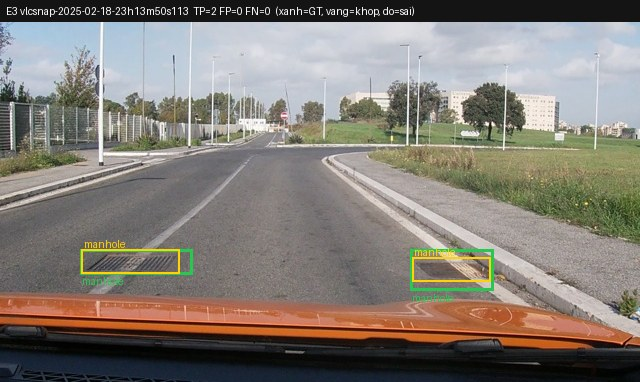

In [10]:
best = json.loads(Path('report/logs/best.json').read_text())['best']
for name in ('e0', best):
    print(subprocess.run([sys.executable, '-m', 'day10.viz', '--pred', f'work/{name}.jsonl', '--name', name.upper()],
                         capture_output=True, text=True, encoding='utf-8').stdout[:400])
Image.open(f'report/figures/{best}_1_good.jpg')

## 8. E4 (ablation data_size) và E5 (GRPO)

In [11]:
print('setup gốc cho E4/E5:', best.upper())
score('work/e4_data_0.1.jsonl', 'E4_data_0.1', 'report/evidence/e4_data_0.1.json', *meta_of('e4_data_0.1'))
# data_size = 1.0 chính là setup gốc (cùng mọi siêu tham số), nên dùng lại dự đoán của nó.
score(f'work/{best}.jsonl', 'E4_data_1.0', 'report/evidence/e4_data_1.0.json', *meta_of(best))

setup gốc cho E4/E5: E3


E4_data_0.1 [test] n=311 valid=1.000 P=0.279 R=0.317 F1=0.297 CI95=0.262-0.333 meanIoU=0.670 FP/img=1.54
   pothole  P=0.206 R=0.240 F1=0.221
   crack    P=0.190 R=0.251 F1=0.216
   manhole  P=0.628 R=0.497 F1=0.555



E4_data_1.0 [test] n=311 valid=0.997 P=0.464 R=0.408 F1=0.434 CI95=0.394-0.475 meanIoU=0.693 FP/img=0.88
   pothole  P=0.301 R=0.231 F1=0.262
   crack    P=0.367 R=0.361 F1=0.364
   manhole  P=0.816 R=0.626 F1=0.708
   other    P=0.000 R=0.000 F1=0.000



In [12]:
print(subprocess.run([sys.executable, '-m', 'pytest', '-q', 'day10/tests/test_reward.py'],
                     capture_output=True, text=True).stdout.strip().splitlines()[-1])
score('work/e5.jsonl', 'E5', 'report/evidence/e5.json', *meta_of('e5'))
hist = [h for h in json.loads(Path('report/logs/e5_log_history.json').read_text()) if 'reward' in h]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot([h['step'] for h in hist], [h['reward'] for h in hist], label='reward trung bình')
ax.plot([h['step'] for h in hist], [h['completions/mean_length'] / 128 for h in hist], label='độ dài / 128')
ax.set_xlabel('bước GRPO'); ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig('report/figures/grpo_reward.png', dpi=110)

10 passed in 0.02s
E5 [test] n=311 valid=1.000 P=0.482 R=0.398 F1=0.436 CI95=0.394-0.476 meanIoU=0.700 FP/img=0.80
   pothole  P=0.333 R=0.248 F1=0.284
   crack    P=0.371 R=0.331 F1=0.350
   manhole  P=0.831 R=0.632 F1=0.718

